# Reconstructing the Sun's global coronal magnetic field


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。 当前为给定磁边界和物理假设的势场外推；边界逆视角另行讨论，严格核心清单暂不包含。

### 观测边界 → 条件日冕势场：模型外推边界任务

**观测：** magnetogram为完整180×360光球径向磁场，单位Gauss。

**目标：** 在内半径1、外源面2.5太阳半径之间计算三个交错网格磁场分量。

**GT：没有独立日冕场真值。** 原方法场仅是同边界和势场假设下的参考计算。

**执行过程：** 去除输入均值实现磁通平衡，solvers.solve通过角向特征分解和径向延拓求解Laplace边值问题；不是从完整内部场测量反演自由体分布。边界trace到内部场也有可讨论的逆问题视角，因此单列model_extrapolation，严格inverse-only核心暂不纳入，而不否认所有逆视角。

**实验与图：** cell7、9、11保留磁图、守恒与径向衰减、源面与经度采样敏感性图；cell5包含主动计算路径。本轮未重跑。图表支持条件外推的数值一致性，不能说明真实日冕磁场精度。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Reconstruct the three-dimensional coronal magnetic vector field from a real solar surface magnetogram despite having measured only the inner radial boundary of an extended spherical atmosphere.

This review actively solves the **entire native180×360 GONG magnetic observation**, without an archived-answer shortcut. The full3D vector field is reconstructed on35 log-radius cells from1 to2.5solar radii. The independently executed original solver is used only for comparison. Observations: NSO/AURA/NSF, with GONG/NISP and NOAA support. The source-surface model gives a conditional field extrapolation, **not an independently measured true corona**.


## 2. Data

The observation is the complete native equal-area GONG synoptic magnetic map for Carrington rotation 2234. No pixel downsampling or field crop is applied.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| magnetogram | (1, 180, 360) | float32 (big-endian FITS precision preserved) | Measured photospheric radial magnetic field in G; axes batch, sine latitude increasing south-to-north, Carrington longitude increasing from the stated edge. |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Instrument | NSO-GONG network | identifier | Magnetic synoptic image product |
| Map observation time | 2020-09-01T13:04:00 | UTC | Last contributor epoch; map is assembled over time |
| Carrington rotation | 2234 | dimensionless | Rotation identifier |
| Diagnostic wavelength | 676.8 | nm | Photospheric spectral line |
| Number of contributing files | 7391 | count | Original image metadata |
| Projection | Cylindrical equal area | dimensionless | Uniform longitude and sine-latitude sampling |
| Longitude edge | 22.0 | degree | Western edge; centers offset by half a degree |
| Longitude spacing | 1.00000 | degree | Original stored increment |
| Sine-latitude increment in original header | 0.0111111 | dimensionless | Original decimal metadata, retained verbatim |
| Exact full-sphere grid increment | 2/180 | dimensionless | Full-sphere finite-volume coordinate definition |
| First axis center reference pixel | 180.500 | pixel | One-based original WCS convention |
| Second axis center reference pixel | 90.5000 | pixel | One-based equatorial reference |
| Central reference longitude | 202 | degree | Original WCS reference value |
| Inner shell radius | 1 | solar radius | Photospheric boundary |
| Outer shell radius | 2.5 | solar radius | Radial-field source-surface assumption |
| Grid and boundary conditions | 35 log-radius cells; periodic longitude; regular poles | dimensionless | Required finite-volume output geometry |
| Noise model | Not supplied | G | Instrument noise and synoptic evolution are not an independent known Gaussian variance |


## 3. Physics

Recover the magnetic vector B in the spherical shell between the photosphere r = 1 solar radius and a spherical source surface r = 2.5 solar radii. The potential-field approximation satisfies


$$
\nabla\times\mathbf B=0,\qquad \nabla\cdot\mathbf B=0,\qquad
\mathbf B=-\nabla\Phi,\qquad \nabla^2\Phi=0.
$$


Φ is a magnetic scalar potential, r is distance from the solar center, θ is colatitude measured southward from the north pole, and φ is increasing Carrington longitude. The observed map specifies the radial component at the inner boundary after subtracting its equal-area mean. This removes the unphysical net magnetic monopole caused by finite observational imbalance. At the outer boundary the two tangential components vanish. Longitude is periodic and the field is regular at both poles. The unknown field is fixed by these boundary assumptions; the observation alone does not establish that the true corona is current free.


The magnetic assumptions are curl B=0, div B=0, with B=−grad Φ and Laplace Φ=0. Measured inner radial B is flux balanced; outer tangential B vanishes. Longitude is periodic; the poles obey finite-volume regularity. The three signed components are on different cell faces. Their declared Gauss scale and physical coordinate locations are retained.


## 4. Method

Separate longitude with a discrete Fourier transform and solve a symmetric latitude eigenproblem for each azimuthal mode. A uniform sine-latitude grid preserves equal surface areas; a uniform log-radius grid permits a simple radial recurrence. Enforce the radial outer boundary for each eigenmode and omit the zero magnetic-monopole mode. Construct an edge-integrated vector potential and obtain magnetic face fluxes by its discrete curl. This preserves discrete divergence cancellation and is more faithful to the stated staggered geometry than differentiating a plotted interpolated field.

The continuum Laplace equation is separated using a source-surface condition, while the benchmark uses the finite-volume eigenfunction discretization with the exact face areas and polar conventions above. At the original geometry, longitude Fourier modes use the periodic finite-difference eigenvalue 4 sin²(πm/360), where m is the integer azimuthal mode index. Comparing against an analytic dipole, checking total flux on every shell and inspecting all three components are useful independent physical validations.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
from pathlib import Path
import sys,time,json,numpy as np,matplotlib.pyplot as plt
from IPython.display import display,Markdown
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data,balance_flux
from src.physics_model import grid,area_factors,flux_divergence
from src.solvers import solve
from src.main import reconstruct
from src.visualization import metrics,plot_maps
raw=load_data(root/'data/raw_data.npz');balanced=balance_flux(raw)
start=time.perf_counter();submission=reconstruct(root/'data/raw_data.npz');runtime=time.perf_counter()-start
fresh={k:v[0]for k,v in submission.items()}
with np.load(root/'evaluation/baseline_reference.npz',allow_pickle=False)as f:original={k:f[k][0]for k in f.files}
g=grid();radii=np.exp(g['rg']);ar,at,ap=area_factors(g)
measurements={'fresh_runtime_seconds':runtime,'removed_measured_mean_gauss':float(raw.astype(np.float64).mean()),'original_agreement':{k:metrics(fresh[k],original[k])for k in fresh},'max_cell_flux_imbalance_G_Rsun2':float(np.max(abs(flux_divergence(fresh,g)))),'max_inner_boundary_error_G':float(np.max(abs(fresh['radial'][0]-balanced)))}
print(json.dumps(measurements,indent=2))

{
  "fresh_runtime_seconds": 0.570677800104022,
  "removed_measured_mean_gauss": -0.11282645460453997,
  "original_agreement": {
    "radial": {
      "ncc": 1.0,
      "nrmse": 0.0
    },
    "polar": {
      "ncc": 0.9999999999999998,
      "nrmse": 4.864039120988965e-19
    },
    "azimuthal": {
      "ncc": 1.0,
      "nrmse": 1.749816391793141e-19
    }
  },
  "max_cell_flux_imbalance_G_Rsun2": 3.469446951953614e-18,
  "max_inner_boundary_error_G": 4.81439776933712e-10
}


### Discrete inverse and magnetic structure with height

Longitude is transformed to mode m. Let Δs, Δφ and Δρ be uniform sine-latitude, longitude and log-radius increments. The latitude matrix has diagonal V(j)+V(j+1)+U(j)μ(m), off-diagonal −V(j+1), and μ(m)=4sin²(πm/Nφ). V and U are ratios of spherical edge lengths to face areas. Its eigenvalues λ and eigenvectors Q separate latitude. Radial roots are z±=F±sqrt(F²−exp(Δρ)), with F=[1+exp(Δρ)+λ sinh(Δρ)(exp(Δρ)−1)]/2. Boundary data determine the growing and decaying radial contributions. The source-surface condition sets their ratio; the monopole mode is excluded. A discrete curl of edge-integrated vector potential gives every face flux.

The observed mean offset is removed from measurements to enforce magnetic flux balance. The maps retain all360longitude cells. **99th-percentile absolute display limits are labeled** to reveal quiet-Sun structure without altering saved arrays. The independent residual panel uses its actual full numerical range.


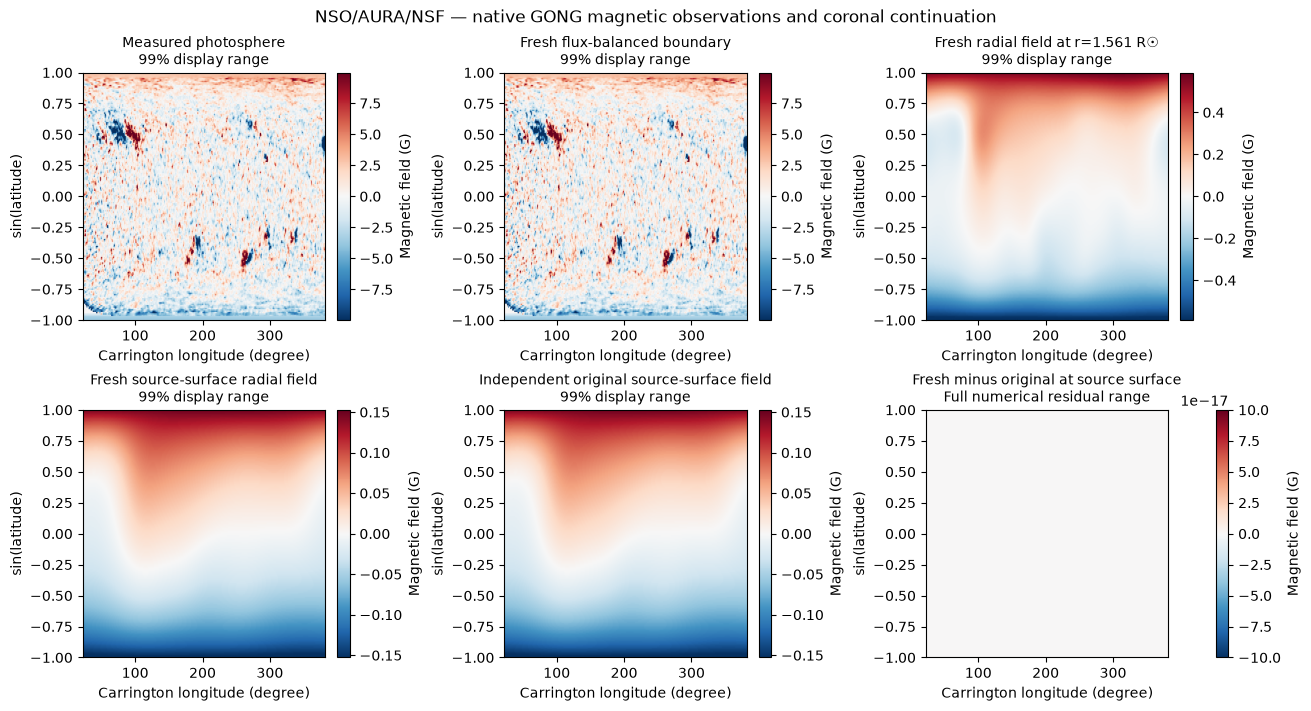

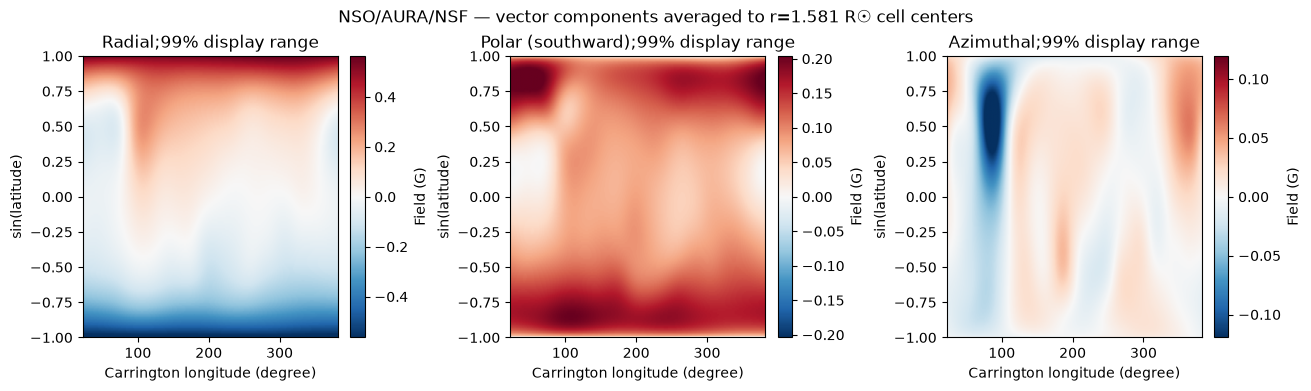

In [2]:
plots={}
plots['magnetic_maps']=plot_maps(raw,fresh,original,radii)
plt.close('all')
display(plots['magnetic_maps']);plt.close(plots['magnetic_maps'])
fig,ax=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
br_center=.5*(fresh['radial'][17]+fresh['radial'][18])
bt_center=.5*(fresh['polar'][17,:-1]+fresh['polar'][17,1:])
bp_center=.5*(fresh['azimuthal'][17,:,:-1]+fresh['azimuthal'][17,:,1:])
for a,x,name in zip(ax,[br_center,bt_center,bp_center],['Radial','Polar (southward)','Azimuthal']):
    vmax=np.percentile(abs(x),99);im=a.imshow(x,origin='lower',aspect='auto',extent=[22,382,-1,1],vmin=-vmax,vmax=vmax,cmap='RdBu_r');fig.colorbar(im,ax=a,label='Field (G)');a.set(title=name+';99% display range',xlabel='Carrington longitude (degree)',ylabel='sin(latitude)')
fig.suptitle(f'NSO/AURA/NSF — vector components averaged to r={np.exp(g["rc"][17]):.3f} R☉ cell centers')
plots['vector_components']=fig;plt.close(fig);display(fig)

### Conservation and radial decay

The finite-volume net flux uses the exact spherical areas and the polar sign convention. Internal cell-face fluxes cancel. Zero magnetic monopole imposes near-zero signed flux through every radius. Unsigned flux and RMS field strength are different physical quantities; they decrease as small-scale surface structure closes with height. These are computed from the fresh full arrays, with no fitted physical rescaling.


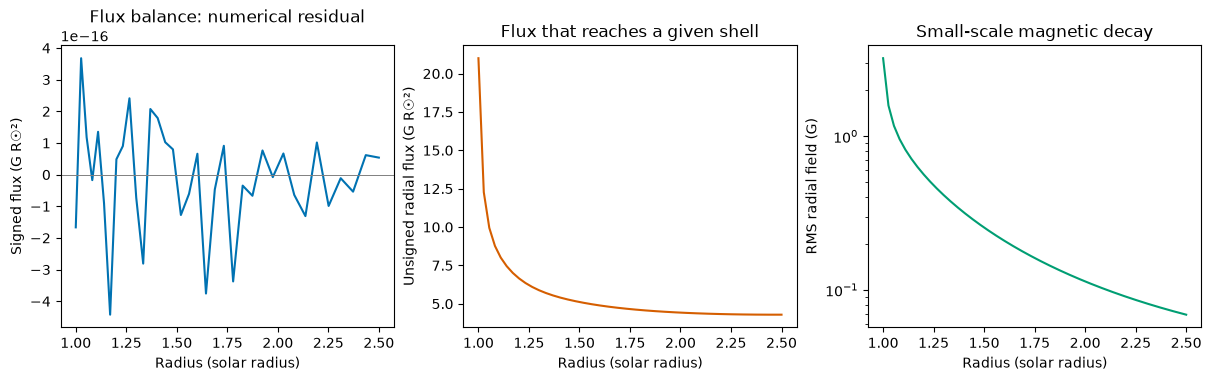

In [3]:
signed_flux=np.sum(fresh['radial']*ar[:,:,None],axis=(1,2))
unsigned_flux=np.sum(abs(fresh['radial'])*ar[:,:,None],axis=(1,2))
rms_radial=np.sqrt(np.mean(fresh['radial']**2,axis=(1,2)))
measurements['max_shell_signed_flux_G_Rsun2']=float(np.max(abs(signed_flux)))
measurements['source_unsigned_flux_G_Rsun2']=float(unsigned_flux[-1])
fig,ax=plt.subplots(1,3,figsize=(12,3.7),layout='constrained')
ax[0].plot(radii,signed_flux,color='#0072B2');ax[0].axhline(0,color='.5',lw=.7);ax[0].set(ylabel='Signed flux (G R☉²)',title='Flux balance: numerical residual')
ax[1].plot(radii,unsigned_flux,color='#D55E00');ax[1].set(ylabel='Unsigned radial flux (G R☉²)',title='Flux that reaches a given shell')
ax[2].semilogy(radii,rms_radial,color='#009E73');ax[2].set(ylabel='RMS radial field (G)',title='Small-scale magnetic decay')
for a in ax:a.set_xlabel('Radius (solar radius)')
plots['radial_physics']=fig;plt.close(fig);display(fig)

### Boundary-model and acquisition sensitivity

The source-surface radius is a model assumption, not a measured knob. Recompute full native reconstructions for2.0,2.5and3.0solar radii and compare their radial outer maps and unsigned flux. The2.5case is freshly solved again, not substituted from the independent original. A separate acquisition experiment retains every second measured longitude at its physical center (1.5degrees after the original edge), balances that actual subset and reconstructs the corresponding180-longitude grid. This assesses angular sampling sensitivity while the benchmark remains native360. No unobserved truth is invented.


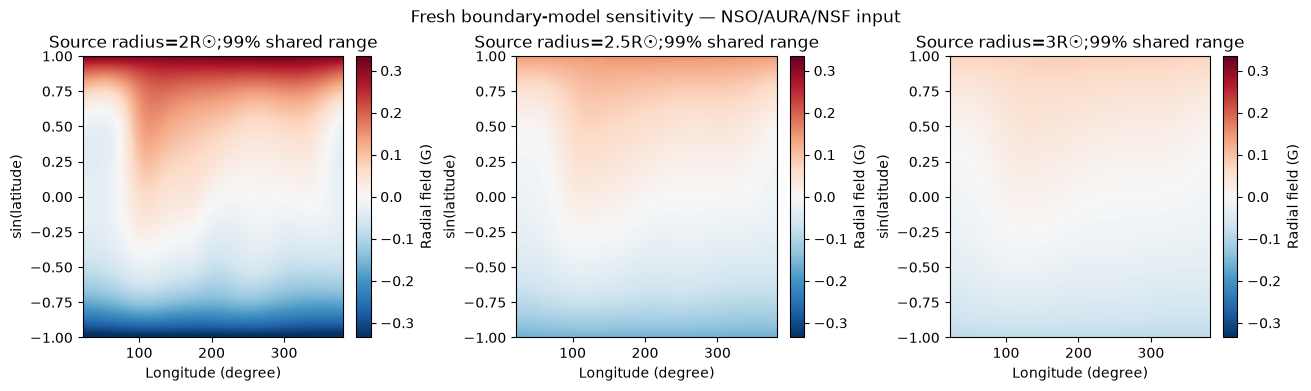

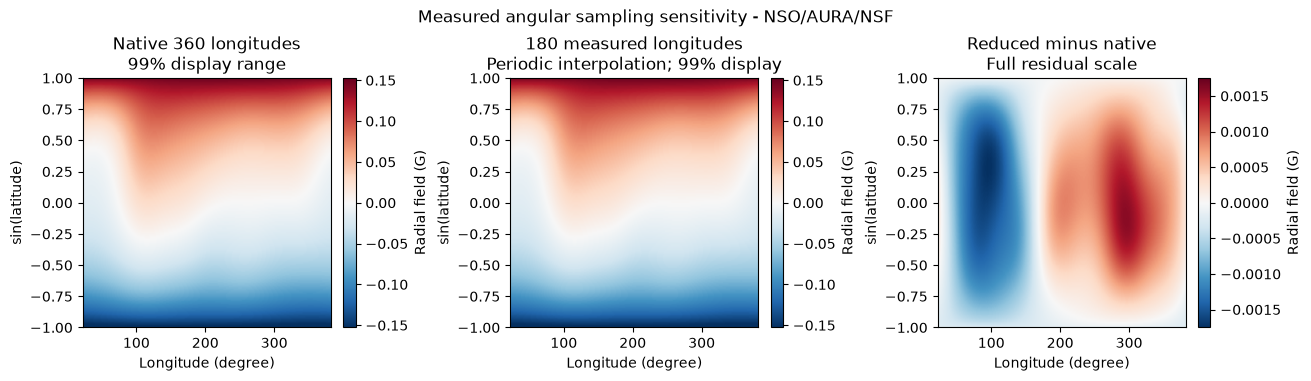

{
  "fresh_runtime_seconds": 0.570677800104022,
  "removed_measured_mean_gauss": -0.11282645460453997,
  "original_agreement": {
    "radial": {
      "ncc": 1.0,
      "nrmse": 0.0
    },
    "polar": {
      "ncc": 0.9999999999999998,
      "nrmse": 4.864039120988965e-19
    },
    "azimuthal": {
      "ncc": 1.0,
      "nrmse": 1.749816391793141e-19
    }
  },
  "max_cell_flux_imbalance_G_Rsun2": 3.469446951953614e-18,
  "max_inner_boundary_error_G": 4.81439776933712e-10,
  "max_shell_signed_flux_G_Rsun2": 4.423544863740858e-16,
  "source_unsigned_flux_G_Rsun2": 4.288133603899058,
  "source_radius_unsigned_flux_G_Rsun2": {
    "2.0": 5.080458627546665,
    "2.5": 4.288133603899054,
    "3.0": 3.69380440436813
  },
  "half_longitude_source_agreement": {
    "ncc": 0.9999317153492367,
    "nrmse": 0.0026187357048137743
  }
}


In [4]:
source_surfaces={rss:solve(balanced,nr=35,rss=rss)for rss in (2.,2.5,3.)}
coarse=raw[:,1::2].astype(np.float64);coarse-=coarse.mean();coarse_fields=solve(coarse)
source_flux={str(rss):float(np.sum(abs(model['radial'][-1]))*(2/180)*(2*np.pi/360)*rss**2)for rss,model in source_surfaces.items()}
measurements['source_radius_unsigned_flux_G_Rsun2']=source_flux
fig,ax=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
vmax=max(np.percentile(abs(model['radial'][-1]),99)for model in source_surfaces.values())
for a,(rss,model)in zip(ax,source_surfaces.items()):
    im=a.imshow(model['radial'][-1],origin='lower',aspect='auto',extent=[22,382,-1,1],vmin=-vmax,vmax=vmax,cmap='RdBu_r');fig.colorbar(im,ax=a,label='Radial field (G)');a.set(title=f'Source radius={rss:g}R☉;99% shared range',xlabel='Longitude (degree)',ylabel='sin(latitude)')
fig.suptitle('Fresh boundary-model sensitivity — NSO/AURA/NSF input')
plots['boundary_sensitivity']=fig;plt.close(fig);display(fig)
phi_native=np.arange(360)+.5;phi_coarse=np.arange(180)*2+1.5
coarse_interp=np.array([np.interp(phi_native,phi_coarse,row,period=360)for row in coarse_fields['radial'][-1]])
measurements['half_longitude_source_agreement']=metrics(coarse_interp,fresh['radial'][-1])
fig,ax=plt.subplots(1,3,figsize=(13,3.7),layout='constrained')
limit=np.percentile(abs(fresh['radial'][-1]),99)
for a,x,title in zip(ax,[fresh['radial'][-1],coarse_interp,coarse_interp-fresh['radial'][-1]],['Native 360 longitudes\n99% display range','180 measured longitudes\nPeriodic interpolation; 99% display','Reduced minus native\nFull residual scale']):
    v=limit if 'residual'not in title else np.max(abs(x));im=a.imshow(x,origin='lower',aspect='auto',extent=[22,382,-1,1],vmin=-v,vmax=v,cmap='RdBu_r');fig.colorbar(im,ax=a,label='Radial field (G)');a.set(title=title,xlabel='Longitude (degree)',ylabel='sin(latitude)')
fig.suptitle('Measured angular sampling sensitivity - NSO/AURA/NSF');plots['sampling_sensitivity']=fig;plt.close(fig);display(fig)
print(json.dumps(measurements,indent=2))

In [5]:
import importlib.util,tempfile
spec=importlib.util.spec_from_file_location('independent_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
with tempfile.TemporaryDirectory()as directory:
    path=Path(directory)/'fresh.npz';np.savez_compressed(path,**submission);report,status=judge.evaluate(path)
print(json.dumps(report,indent=2));assert status==0

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "radial_ncc": 1.0,
    "radial_nrmse": 0.0,
    "polar_ncc": 0.9999999999999998,
    "polar_nrmse": 4.864039120988965e-19,
    "azimuthal_ncc": 1.0,
    "azimuthal_nrmse": 1.749816391793141e-19
  },
  "thresholds": {
    "radial_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "radial_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "polar_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "polar_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "azimuthal_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "azimuthal_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}


## 6. Conclusion

### Independent evaluator and limits

The next cell evaluates the freshly recomputed full vector field. Each component separately meets standard uncentered cosine similarity and dynamic-range-normalized RMS boundaries. Exact original agreement tests the local mathematics; it does not prove that a current-free model reproduces the real corona. A synoptic map combines7391inputs over time, polar observations are uncertain, and non-potential active regions and solar-wind dynamics lie outside the approximation. The source-surface and sampling experiments show conditional sensitivity rather than new physical ground truth.

Zero signed flux is a conservation constraint and differs from unsigned flux or RMS field. Source-surface-radius and longitude-sampling runs test conditional boundary assumptions. The complete synoptic map mixes time-dependent observations and does not provide instantaneous three-dimensional coronal truth.
